# 34. Perturbation of Spectral Subspaces
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Eigenvectors depend on the gap. For $A=\mathrm{diag}(1+\gamma,1-\gamma)$ perturbed by $\varepsilon\begin{bmatrix}0&1\\1&0\end{bmatrix}$, the angle by which the eigenvectors rotate, as a function of $\varepsilon$ for gaps $2\gamma=1,10^{-1},10^{-2},10^{-3}$. It is roughly $\varepsilon/(2\gamma)$ while $\varepsilon\ll\gamma$, the ratio of perturbation to gap, and saturates at $45^\circ$ once $\varepsilon$ exceeds the gap. The eigenvalues meanwhile move by at most $\varepsilon$.

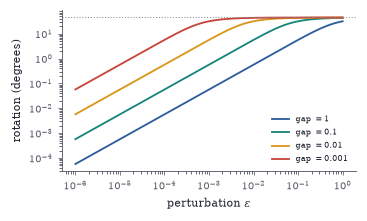

In [2]:
eps_ = np.logspace(-6, 0, 200)
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
for g, col in zip([0.5, 0.05, 0.005, 0.0005], [BLUE, TEAL, GOLD, RED]):
    ax.loglog(eps_, np.degrees(0.5 * np.arctan(eps_ / g)), color=col, label=rf"gap $={2*g:g}$")
ax.axhline(45, color=GRAY, ls=":", lw=0.7); ax.set_xlabel(r"perturbation $\varepsilon$"); ax.set_ylabel("rotation (degrees)"); ax.legend(fontsize=5.5)

Principal angles between two planes in $\mathbb{R}^3$. The planes meet along a line, so the first principal angle is $0$ (both first principal vectors lie on the intersection, black); the second principal vectors (blue and red) are perpendicular to that line within each plane, and the angle between them, here $50^\circ$, is the dihedral angle. In $\mathbb{R}^n$, two $k$-planes generally meet at $k$ angles, and two planes in $\mathbb{R}^4$ can be at a positive angle in every direction.

Text(0.5, 0.92, '$\\theta_1=0^\\circ$, $\\theta_2=50^\\circ$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


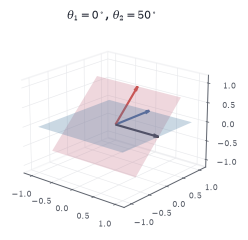

In [3]:
ax = ax3d(plt.figure(figsize=(W * 0.5, W * 0.45)), elev=20, azim=-50, lim=1.2)
Xp = np.array([[1, 0], [0, 1], [0, 0.0]]); th = np.radians(50); Yp = np.array([[1, 0], [0, np.cos(th)], [0, np.sin(th)]])
Um, cs, Vmt = np.linalg.svd(Xp.T @ Yp); PX, PY = Xp @ Um, Yp @ Vmt.T
for B_, col in [(Xp, SKY), (Yp, ROSE)]:
    s_, t_ = np.meshgrid(np.linspace(-1, 1, 2), np.linspace(-1, 1, 2)); pts_ = B_[:, :1, None] * s_ + B_[:, 1:, None] * t_
    ax.plot_surface(pts_[0], pts_[1], pts_[2], color=col, alpha=0.3)
arrow3d(ax, PX[:, 0], color=INK); arrow3d(ax, PX[:, 1] * np.sign(PX[1, 1]), color=BLUE); arrow3d(ax, PY[:, 1] * np.sign(PY[1, 1]), color=RED)
ax.set_title(rf"$\theta_1={np.degrees(np.arccos(min(cs[0], 1))):.0f}^\circ$, $\theta_2={np.degrees(np.arccos(cs[1])):.0f}^\circ$", fontsize=7)

The $\sin\Theta$ theorem in action. A $40\times40$ symmetric matrix has a cluster of $3$ eigenvalues separated by a gap from the rest; random symmetric perturbations $H$ of increasing norm are added, and the largest principal angle between the old and new $3$-dimensional invariant subspaces is recorded (dots, three gaps). The dashed lines are the bound $\pi\lVert H\rVert/\mathrm{gap}$; the angle grows linearly with $\lVert H\rVert/\mathrm{gap}$, as predicted, until it saturates.

(1e-06, 2)

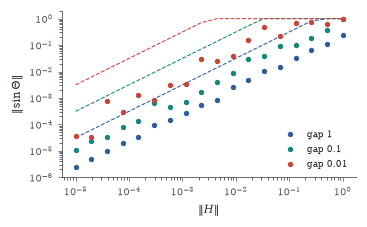

In [4]:
rng = np.random.default_rng(4); n = 40; Q, _ = np.linalg.qr(rng.normal(size=(n, n)))
fig, ax = plt.subplots(figsize=(W * 0.7, 1.95))
for gap, col in [(1.0, BLUE), (0.1, TEAL), (0.01, RED)]:
    lam = np.r_[np.array([3.0, 2.8, 2.6]) + gap, np.linspace(-2, 2.6, n - 3)]; A = Q @ np.diag(lam) @ Q.T; X = Q[:, :3]
    hs = np.logspace(-5, 0, 18); ang = []
    for h in hs:
        Hm = rng.normal(size=(n, n)); Hm = (Hm + Hm.T) / 2; Hm *= h / np.linalg.norm(Hm, 2)
        w, V = np.linalg.eigh(A + Hm); Xh = V[:, -3:]; ang.append(np.linalg.norm(Xh.T @ Q[:, 3:], 2))
    ax.loglog(hs, ang, "o", color=col, ms=2.5, label=f"gap {gap:g}"); ax.loglog(hs, np.minimum(np.pi * hs / gap, 1), "--", color=col, lw=0.7)
ax.set_xlabel(r"$\|H\|$"); ax.set_ylabel(r"$\|\sin\Theta\|$"); ax.legend(fontsize=6); ax.set_ylim(1e-6, 2)

The BBP transition. For the spiked model $\theta uu^{\mathsf T}+W/\sqrt{n}$ with $n=600$, the squared overlap $|\langle\hat u,u\rangle|^2$ between the top eigenvector and the planted direction (blue dots, $4$ trials per $\theta$) follows the limit curve $\max(0,1-\theta^{-2})$ (red): no information below $\theta=1$, partial recovery above. Grey squares: the guarantee from Davis–Kahan (case 2, with the residual $\lVert Wu\rVert/\sqrt n\approx1$ and the separation $\theta-\lambda_2$), which is valid but only becomes informative for $\theta\gtrsim3$.

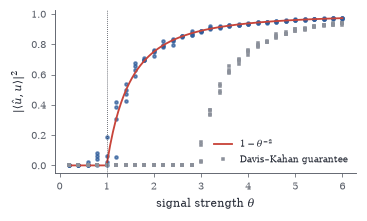

In [5]:
rng = np.random.default_rng(0); n = 600; thetas = np.linspace(0.2, 6, 30); u = rng.normal(size=n); u /= np.linalg.norm(u); ov = []
for th in thetas:
    for _ in range(4):
        Wm = rng.normal(size=(n, n)); Wm = (Wm + Wm.T) / np.sqrt(2 * n); w, V = np.linalg.eigh(th * np.outer(u, u) + Wm)
        dk = 1 - min(1, np.linalg.norm(Wm @ u) / (th - w[-2])) ** 2 if th > w[-2] else 0.0; ov.append((th, (V[:, -1] @ u) ** 2, dk))
ov = np.array(ov); tt = np.linspace(0.2, 6, 200)
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
ax.plot(ov[:, 0], ov[:, 1], "o", color=BLUE, ms=2, alpha=0.7); ax.plot(tt, np.maximum(0, 1 - tt**-2.0), color=RED, label=r"$1-\theta^{-2}$")
ax.plot(ov[:, 0], ov[:, 2], "s", color=GRAY, ms=1.8, label="Davis–Kahan guarantee"); ax.axvline(1, color=INK, lw=0.5, ls=":")
ax.set_xlabel(r"signal strength $\theta$"); ax.set_ylabel(r"$|\langle\hat u,u\rangle|^2$"); ax.legend(fontsize=6)

In [6]:
rng = np.random.default_rng(2); n = 30; Q, _ = np.linalg.qr(rng.normal(size=(n, n))); A30 = Q @ np.diag(np.arange(1.0, n + 1)) @ Q.T
Hm = rng.normal(size=(n, n)); Hm = (Hm + Hm.T) / 2; Hm *= 0.2 / np.linalg.norm(Hm, 2)
X = Q[:, -5:]; w, V = np.linalg.eigh(A30 + Hm); Xh_perp = V[:, :-5]
sinT = np.linalg.norm(Xh_perp.T @ X, 2); delta = 26.0 - w[-6]
print(f"||sin Theta|| = {sinT:.5f}   bound ||HX||/delta = {np.linalg.norm(Hm @ X, 2) / delta:.5f}   (delta = {delta:.3f})")

||sin Theta|| = 0.02176   bound ||HX||/delta = 0.13068   (delta = 1.051)


In [7]:
rng = np.random.default_rng(3); n = 200; lab = np.r_[np.ones(100), -np.ones(100)]
Pm = np.where(np.equal.outer(lab, lab), 0.15, 0.03); Ad = np.triu(rng.random((n, n)) < Pm, 1); Ad = (Ad + Ad.T).astype(float)
w, V = np.linalg.eigh(Ad); v2 = V[:, -2]; acc = max(np.mean(np.sign(v2) == lab), np.mean(np.sign(v2) == -lab))
print(f"top eigenvalues: {np.round(w[-3:], 2)}   fraction of vertices correctly assigned: {acc:.3f}")

top eigenvalues: [ 7.55 13.21 19.02]   fraction of vertices correctly assigned: 1.000
